# Week 4 practical: feature transformations
**Lecturer solutions · Data-driven AI · BSc final year · 60 minutes**

## Exercise-to-slide mapping
Slide numbers below are the **physical slide positions, counting the title slide as slide 1**, in
`Week04_Lecture01_Feature_Engineering_PartA.pptx` (28 slides).

| Activity | What you will implement or explain | Exact lecture slides | Core time |
| --- | --- | --- | ---: |
| Setup | Open in Colab, import packages and create the simulated data | Preparation for the exercises below | 5 min |
| Exercise 1 | Diagnose a right-skewed feature and inspect its relationship with a target | **8**, “Transformation Techniques”; **9–10**, “Logarithmic transformation” | 6 min |
| Exercise 2 | Apply `log1p`, square root and linear scaling; compare distributions and distances | **8**, “Transformation Techniques”; **9–10**, “Logarithmic transformation” | 9 min |
| Exercise 3 | Train the same linear regression with raw, log and square-root features; calculate validation MSE | **10**, “Logarithmic transformation”; **11**, “Let’s Review (Mean Squared Error)” | 9 min |
| Exercise 4 | Learn Box–Cox λ from training data; plot before/after and the function family; compare MSE | **12**, “Box-Cox Transformation”; **11**, MSE | 12 min |
| Exercise 5 | Learn Yeo–Johnson λ for negative, zero and positive values; visualise and invert the transformation | **13**, “Yeo-Johnson Transformation” | 14 min |
| Exercise 6 | Recommend transformations and evaluate the selected parcel model on the reserved test set | **8**, transformation choices; **11–13**, MSE and power transformations | 5 min |
| **Core total** | **Setup plus Exercises 1–6** | | **60 min** |
| Optional A | Check domains for all six functions on slide 8 and implement the two power families | **8, 12, 13**; implementation extension | Extra: 20 min |
| Optional B | Compare pipelines with cross-validation, fitting λ separately inside each fold | **11–13**; cross-validation is additional practical material | Extra: 15 min |
| Optional C | Change the target relationship and find a case where a transformation makes prediction worse | **8, 11–12**; additional modelling example | Extra: 10 min |

**Scenario:** you are helping a parcel-delivery hub understand parcel handling and daily stock changes.
These examples use different data from the lecture's class-separation, website-visit and customer examples.
Complete the core work first. Optional exercises are for students who finish early.


## Lecturer guidance
This edition contains complete code, worked discussion answers and saved outputs, including the optional work.
Give students the **Student** edition. Both editions use identical seeds, data and exercise numbering.

Suggested delivery: introduce the scenario and split in the first 5 minutes. Walk around while students
implement the short `TODO` sections. At approximately minute 30, move to Box–Cox; at minute 42, move to
Yeo–Johnson. Use the final 5 minutes for the recommendation and exit questions.

Emphasise the distinction between making a feature more symmetric and improving a model.
The simulation deliberately contains a log-shaped target relationship. Box–Cox's likelihood criterion
does not use that target. The signed daily-stock data form a separate distribution example, so their
statistics must not be compared with the parcel model's MSE as if they were the same prediction task.


## Setup · 5 minutes
1. Open [Google Colab](https://colab.research.google.com/), choose **File → Upload notebook**, and upload this `.ipynb` file.
2. Save a copy to your Drive. A standard **CPU** runtime is sufficient.
3. Run the setup cells in order with **Shift+Enter**. Then work through Exercises 1–6.
4. Replace each `None` marked `TODO` with your code, rerun that cell, and rerun its following plot cells.
   Edit the answer cells to record your interpretation. Starter cells print a reminder while a task is incomplete,
   so **Run all** works before you fill the blanks.

The notebook generates its own small datasets. It needs no external data files, API keys or GPU.
NumPy, pandas, Matplotlib, SciPy and scikit-learn are normally present in Colab. The next cell installs
only missing packages, without upgrading packages that are already installed.


In [1]:
# Provided setup. Run this cell first.
import importlib.util
import subprocess
import sys

required_packages = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
}
missing = [package for module, package in required_packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Required packages are available.')

# Equivalent manual Colab command, if ever needed:
# %pip install -q numpy pandas matplotlib scipy scikit-learn


Required packages are available.


In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer, FunctionTransformer
from IPython.display import display

SEED = 42
RUN_OPTIONAL = True  # Students: change to True only when starting optional work.

plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.18,
})
BLUE, TEAL, ORANGE, PURPLE = '#245A81', '#00897B', '#DA8B2C', '#7957A0'

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__)
print('SciPy:', scipy.__version__, '| scikit-learn:', sklearn.__version__)
print('Matplotlib:', matplotlib.__version__)


Python: 3.12.14
NumPy: 2.3.5 | pandas: 2.2.3
SciPy: 1.17.0 | scikit-learn: 1.8.0
Matplotlib: 3.10.8


## The data and the prediction task
We use two **separate simulated datasets** from the same fictional parcel hub:

| Dataset | One row represents | Variables | Purpose |
| --- | --- | --- | --- |
| `parcels` | One parcel | `mass_kg` > 0 and `handling_seconds` | Compare feature transformations using the same linear regression |
| `daily_stock` | One independent daily snapshot | `net_stock_change_kg`, which may be negative, zero or positive | Explore Yeo–Johnson on a signed feature |

A negative stock change means more parcel mass left the hub than arrived. Zero means no net change.
The daily snapshots are independent simulated observations, rather than a time-series forecasting task.

The parcel simulation deliberately gives handling time a diminishing-return relationship with mass,
plus random noise. This makes the effect of a suitable transformation visible. It is an illustration,
rather than a claim about real parcel-handling physics.

**Keep the target in seconds throughout.** Only the input feature changes.

For parcels we reserve **60% training, 20% validation and 20% test**:
learn model coefficients and λ on training data, compare alternatives on validation data, and use the
reserved test data at the end. The stock data have their own 80%/20% split for distribution diagnostics.


In [3]:
# Provided data generation and splits. Keep the seeds unchanged for comparison.
rng = np.random.default_rng(SEED)
mass_kg = rng.lognormal(mean=0.6, sigma=1.1, size=900)
handling_seconds = 30 + 18 * np.log1p(mass_kg) + rng.normal(0, 3.5, size=900)
parcels = pd.DataFrame({'mass_kg': mass_kg, 'handling_seconds': handling_seconds})

all_indices = np.arange(len(parcels))
dev_idx, test_idx = train_test_split(all_indices, test_size=0.20, random_state=SEED)
train_idx, val_idx = train_test_split(dev_idx, test_size=0.25, random_state=SEED)
X = parcels[['mass_kg']].to_numpy()  # sklearn expects (number of rows, number of features)
y = parcels['handling_seconds'].to_numpy()
X_train, X_val, X_test = X[train_idx], X[val_idx], X[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
x_train = X_train.ravel()  # one-dimensional version for histograms and NumPy exercises

stock_rng = np.random.default_rng(2026)
stock_change = stock_rng.exponential(scale=8, size=600) - 4
stock_change[::25] = 0  # include exact zeros
daily_stock = pd.DataFrame({'net_stock_change_kg': stock_change})
S_train, S_holdout = train_test_split(
    daily_stock[['net_stock_change_kg']].to_numpy(), test_size=0.20, random_state=SEED
)

assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
print(f'Parcels: {len(X_train)} training, {len(X_val)} validation, {len(X_test)} test')
print(f'Stock snapshots: {len(S_train)} training, {len(S_holdout)} holdout')
display(parcels.iloc[train_idx[:5]].reset_index(drop=True))


Parcels: 540 training, 180 validation, 180 test
Stock snapshots: 480 training, 120 holdout


,mass_kg,handling_seconds
0,4.682225,64.507425
1,4.217401,52.360817
2,0.285316,41.509386
3,2.335243,54.514000
4,2.352284,50.882427


### Provided plotting helpers
Run the next cell without editing it. The helpers draw labelled figures and format results.
Your implementation work starts at **Exercise 1**.


In [4]:
#@title Provided plotting helpers (run without editing)
def describe_views(views):
    """Summarise a dictionary of one-dimensional feature representations."""
    return pd.DataFrame({name: {
        'Minimum': np.min(values), 'Median': np.median(values),
        'Maximum': np.max(values), 'Sample skewness': pd.Series(np.ravel(values)).skew()
    } for name, values in views.items()}).T

def histogram_grid(views, title, labels=None):
    """Each representation has its own x-axis units; histogram counts are comparable."""
    n = len(views)
    cols = min(2, n)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(11, 3.3 * rows), squeeze=False,
                             layout='constrained')
    palette = [BLUE, TEAL, ORANGE, PURPLE]
    for ax, (name, values), colour in zip(axes.flat, views.items(), palette * rows):
        values = np.asarray(values).ravel()
        ax.hist(values, bins=30, color=colour, alpha=0.85, edgecolor='white')
        ax.set(title=f'{name}: skew = {pd.Series(values).skew():.2f}',
               xlabel=(labels or {}).get(name, name), ylabel='Number of observations')
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)
    fig.suptitle(title, fontweight='bold')
    plt.show()

def plot_power_family(method, learned_lambda=None):
    """Plot unstandardised functions, including the learned curve when available."""
    is_box = method == 'box-cox'
    grid = np.linspace(0.2, 5, 300) if is_box else np.linspace(-4, 4, 300)
    function = stats.boxcox if is_box else stats.yeojohnson
    lambdas = [-1, 0, 0.5, 1, 2] if is_box else [0, 0.5, 1, 1.5, 2]
    fig, ax = plt.subplots(figsize=(8, 4.6), layout='constrained')
    for lam in lambdas:
        ax.plot(grid, function(grid, lmbda=lam), linewidth=2, label=f'λ = {lam:g}')
    if learned_lambda is not None:
        ax.plot(grid, function(grid, lmbda=learned_lambda), color='black',
                linestyle='--', linewidth=2.7, label=f'Learned λ = {learned_lambda:.3f}')
    ax.axhline(0, color='grey', linewidth=0.7)
    ax.axvline(0, color='grey', linewidth=0.7)
    ax.set(title=('Box–Cox' if is_box else 'Yeo–Johnson') + ': how λ changes the function',
           xlabel='Original input value, x', ylabel='Transformed value, Tλ(x)')
    ax.legend(fontsize=9, ncol=2)
    plt.show()

def validation_table():
    """All candidates use the same training and validation rows and unchanged target."""
    return pd.DataFrame.from_dict(validation_scores, orient='index',
                                  columns=['Validation MSE (seconds²)']).sort_values(
                                      'Validation MSE (seconds²)')

def plot_model_fits(registry, names, X_observed, y_observed):
    """The line is linear in each model's own feature coordinates."""
    names = [name for name in names if name in registry]
    fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 4), squeeze=False, sharey=True,
                             layout='constrained')
    grid = np.linspace(X_observed.min(), X_observed.max(), 300).reshape(-1, 1)
    labels = {'Raw': 'Mass (kg)', 'log1p': 'ln(1 + mass)', 'Square root': '√mass',
              'Box–Cox': 'Box–Cox(mass)'}
    for ax, name, colour in zip(axes.flat, names, [BLUE, TEAL, ORANGE, PURPLE]):
        model, transform = registry[name]
        ax.scatter(transform(X_observed).ravel(), y_observed, s=19, alpha=0.45, color=BLUE,
                   label='Validation parcels')
        ax.plot(transform(grid).ravel(), model.predict(transform(grid)), linewidth=2.5,
                color=colour, label='Fitted linear model')
        ax.set(title=name, xlabel=labels.get(name, name), ylabel='Handling time (seconds)')
        ax.legend(fontsize=8)
    plt.show()

print('Plotting helpers are ready.')


Plotting helpers are ready.


## Exercise 1 · Diagnose the feature · 6 minutes
**Slides 8–10.** Use **training data** to explore the feature before choosing a transformation.

Run the supplied plots. Then calculate the minimum, median and sample skewness of `x_train`.
For the skewness calculation, use `pd.Series(x_train).skew()`.
A large positive skewness indicates a long right tail. A skewness near zero alone does not prove normality.


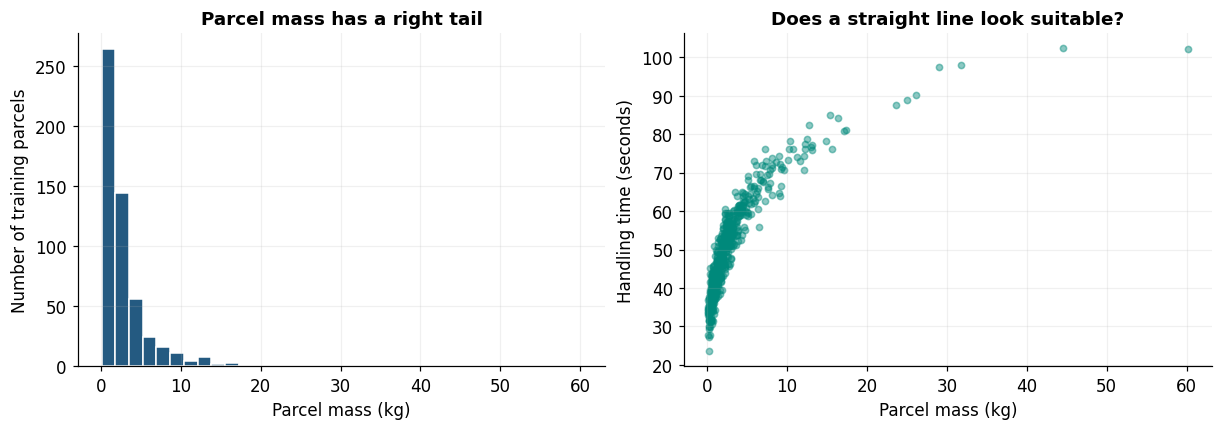

In [5]:
# Provided visual inspection of the training parcels.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
axes[0].hist(x_train, bins=35, color=BLUE, edgecolor='white')
axes[0].set(title='Parcel mass has a right tail', xlabel='Parcel mass (kg)',
            ylabel='Number of training parcels')
axes[1].scatter(x_train, y_train, s=17, alpha=0.45, color=TEAL)
axes[1].set(title='Does a straight line look suitable?', xlabel='Parcel mass (kg)',
            ylabel='Handling time (seconds)')
plt.show()


In [6]:
mass_minimum = np.min(x_train)
mass_median = np.median(x_train)
mass_skewness = pd.Series(x_train).skew()
if any(value is None for value in (mass_minimum, mass_median, mass_skewness)):
    print('Exercise 1: replace the three TODO values, then rerun this cell.')
else:
    display(pd.Series({'Minimum mass (kg)': mass_minimum,
                       'Median mass (kg)': mass_median,
                       'Sample skewness': mass_skewness}).to_frame('Training data'))


,Training data
Minimum mass (kg),0.108249
Median mass (kg),1.873929
Sample skewness,5.911402


**Discuss and record your answers**

1. What in the histogram shows right skewness? Are a few large masses necessarily errors?
2. Does the target relationship appear linear in the raw feature?
3. Which methods from slide 8 would you try first, and why?


**Lecturer solution**

1. Most masses are small, with a few much larger values forming a right tail. The mean/median and
   positive skewness help describe this. An unusual parcel may be valid, so do not delete it just
   because it is large.
2. Handling time rises quickly at small masses and then more slowly. The relationship is curved in
   raw mass, so a single straight line will have a systematic mismatch.
3. Logarithm and square root compress large positive values. Linear scaling changes units but leaves
   skewness unchanged. A square or exponential would accentuate large positive values.


## Exercise 2 · Fixed transformations · 9 minutes
**Slides 8–10.** Fill the three lines below using `np.log1p`, `np.sqrt` and division by 5.
Keep `x_train` unchanged and store new arrays.

- `np.log(x)` is the natural logarithm, with domain $x>0$.
- `np.log1p(x)` calculates $\ln(1+x)$, with domain $x>-1$; it includes zero.
- Square root has domain $x\geq0$ for real outputs.

All parcel masses are positive, so these transformations are defined for this feature.
Also compare how the gaps between **1 kg, 2 kg and 20 kg** change.


Self-checks passed. Notice that the x-axis units change between panels.


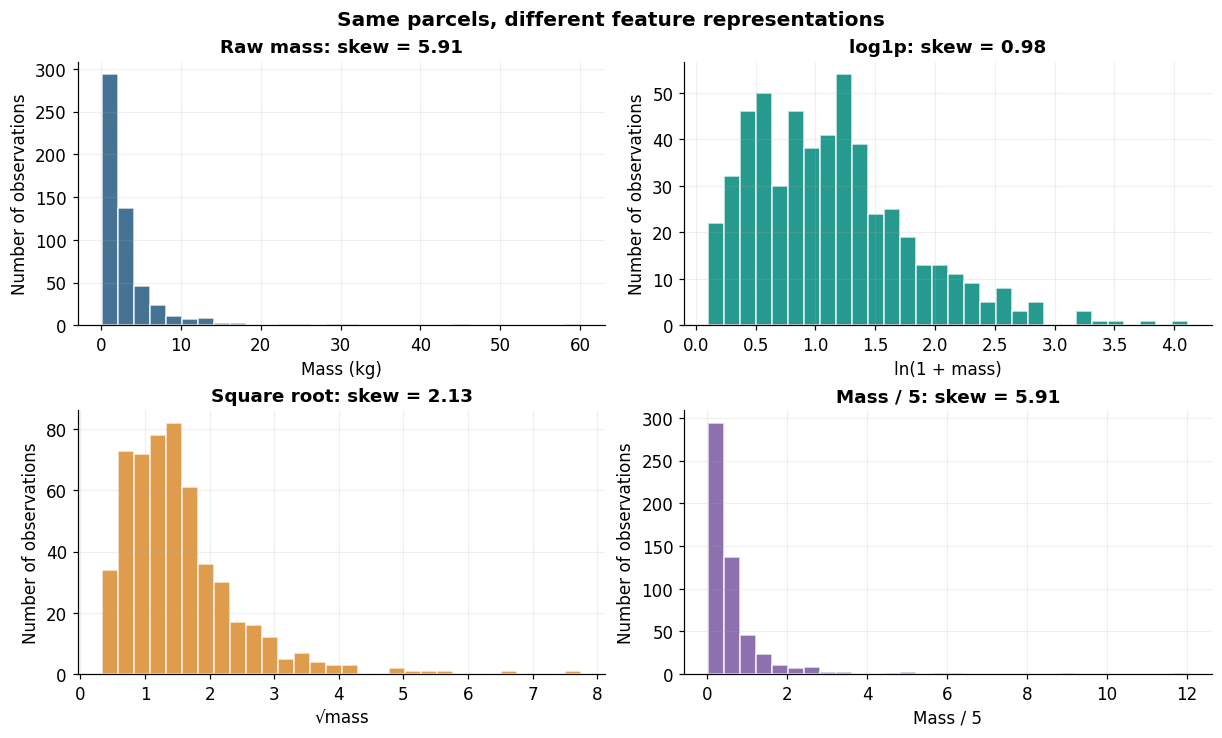

,Minimum,Median,Maximum,Sample skewness
Raw mass,0.1082,1.8739,60.1438,5.9114
log1p,0.1028,1.0557,4.1132,0.9818
Square root,0.3290,1.3689,7.7552,2.1293
Mass / 5,0.0216,0.3748,12.0288,5.9114


,Mass (kg),log1p,Square root,Mass / 5
0,1.0,0.6931,1.0000,0.2
1,2.0,1.0986,1.4142,0.4
2,20.0,3.0445,4.4721,4.0


In [7]:
log_train = np.log1p(x_train)
sqrt_train = np.sqrt(x_train)
scaled_train = x_train / 5
if any(values is None for values in (log_train, sqrt_train, scaled_train)):
    print('Exercise 2: complete log_train, sqrt_train and scaled_train to see the comparison.')
else:
    assert np.allclose(np.expm1(log_train), x_train), 'Check the log1p calculation.'
    assert np.all(sqrt_train >= 0) and np.allclose(sqrt_train**2, x_train), 'Check square root.'
    assert np.isclose(pd.Series(scaled_train).skew(), pd.Series(x_train).skew())
    fixed_views = {'Raw mass': x_train, 'log1p': log_train,
                   'Square root': sqrt_train, 'Mass / 5': scaled_train}
    histogram_grid(fixed_views, 'Same parcels, different feature representations', labels={
        'Raw mass': 'Mass (kg)', 'log1p': 'ln(1 + mass)',
        'Square root': '√mass', 'Mass / 5': 'Mass / 5'})
    display(describe_views(fixed_views).round(4))
    probe = np.array([1.0, 2.0, 20.0])
    gap_table = pd.DataFrame({'Mass (kg)': probe, 'log1p': np.log1p(probe),
                              'Square root': np.sqrt(probe), 'Mass / 5': probe / 5})
    display(gap_table.round(4))
    print('Self-checks passed. Notice that the x-axis units change between panels.')


**Discuss and record your answers**

1. Which transformation most reduces the positive skewness here?
2. Does dividing by 5 change the distribution's shape? Explain using the skewness values.
3. Do log and square root preserve the order of these positive masses? What happens to the gaps?


**Lecturer solution**

1. Read the sample-skewness table: log1p produces the smallest positive skewness among the three
   transformed representations in this comparison. Square root compresses the right tail less strongly.
2. Dividing by a positive constant changes units and absolute spread, but preserves distribution shape
   and skewness. It also preserves the raw linear-regression predictions when an intercept is fitted.
3. Both are strictly increasing on the positive domain, so order stays the same. Gaps involving large
   values shrink relative to gaps at small values. Compression does not mean an input value must
   always become numerically smaller; for example, square root increases numbers between 0 and 1.


## Exercise 3 · Does the same linear model improve? · 9 minutes
**Slides 10–11.** Predict `handling_seconds` from one feature. Keep the model, rows and target unchanged.
The supplied cell fits the raw baseline. In the next cell, complete the three lines inside the loop:
fit a `LinearRegression`, predict the validation targets, and calculate `mean_squared_error`.

$$\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2$$

Lower is better. Here MSE is in **seconds squared**. RMSE is its square root, in seconds.
We are predicting a number, so MSE is appropriate; classification accuracy is not used.
A feature does not have to be normally distributed for linear regression to make good predictions.


In [8]:
# Provided baseline. Rerunning this cell resets the comparison table.
model_registry = {}
validation_scores = {}

raw_model = LinearRegression().fit(X_train, y_train)
raw_validation_prediction = raw_model.predict(X_val)
raw_validation_mse = mean_squared_error(y_val, raw_validation_prediction)
model_registry['Raw'] = (raw_model, lambda values: values)
validation_scores['Raw'] = raw_validation_mse
display(validation_table().round(3))


,Validation MSE (seconds²)
Raw,48.211


,Validation MSE (seconds²)
log1p,12.734
Square root,16.420
Raw,48.211


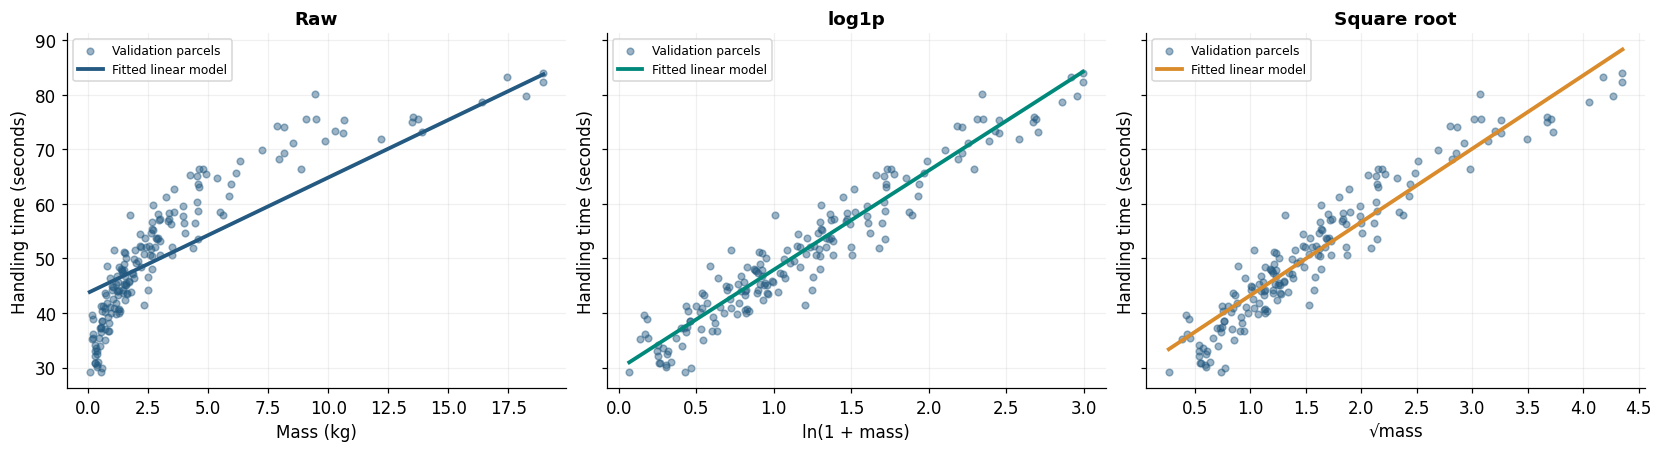

In [9]:
# Complete the same three lines for both transformations via this loop.
for name, transform in [('log1p', np.log1p), ('Square root', np.sqrt)]:
    X_train_transformed = transform(X_train)
    X_val_transformed = transform(X_val)

    model = LinearRegression().fit(X_train_transformed, y_train)
    validation_prediction = model.predict(X_val_transformed)
    validation_mse = mean_squared_error(y_val, validation_prediction)

    if model is None or validation_prediction is None or validation_mse is None:
        print(f'{name}: complete the three TODO lines.')
    else:
        model_registry[name] = (model, transform)
        validation_scores[name] = validation_mse

display(validation_table().round(3))
plot_model_fits(model_registry, ['Raw', 'log1p', 'Square root'], X_val, y_val)


**Discuss and record your answers**

1. Which feature representation gives the smallest validation MSE? Calculate its percentage
   reduction from the raw baseline: `100 * (raw_mse - transformed_mse) / raw_mse`.
2. Why can the same linear model fit better after a nonlinear feature transformation?
3. Would the improvement necessarily occur with a different target relationship?


**Lecturer solution**

1. The saved run gives approximately **48.211** for raw mass, **12.734** for log1p and **16.420** for square root.
   The log1p representation reduces validation MSE by approximately **73.6%** relative to raw mass.
   Small differences across package versions are possible.
2. The log-shaped representation makes this simulated target relationship closer to a straight line.
   The coefficients change because we retrain, while the algorithm remains ordinary linear regression.
3. No. The data generation deliberately includes a log1p relationship. Another relationship may favour
   raw inputs or another transformation. Optional C demonstrates this directly.


## Exercise 4 · Box–Cox and a learned λ · 12 minutes
**Slides 12 and 11.** Box–Cox selects a power parameter from data instead of fixing a log or square root.
Its domain is **strictly positive** inputs, $x>0$.

$$T_\lambda(x)=\begin{cases}(x^\lambda-1)/\lambda,&\lambda\ne0\\\ln(x),&\lambda=0.\end{cases}$$

Complete the three lines below. Use `PowerTransformer(method='box-cox', standardize=False)`.
Call **`fit_transform` on `X_train`** and **`transform` on `X_val`**.
The fitted parameter is available as `bc.lambdas_[0]`.

We set `standardize=False` so the figures show the power function itself. The default also applies
centring and scaling after the transformation. The learned λ uses a maximum-likelihood criterion
for the feature distribution. It does **not** minimise the regression model's MSE.


Learned Box–Cox λ, fitted on training parcels only: -0.009919


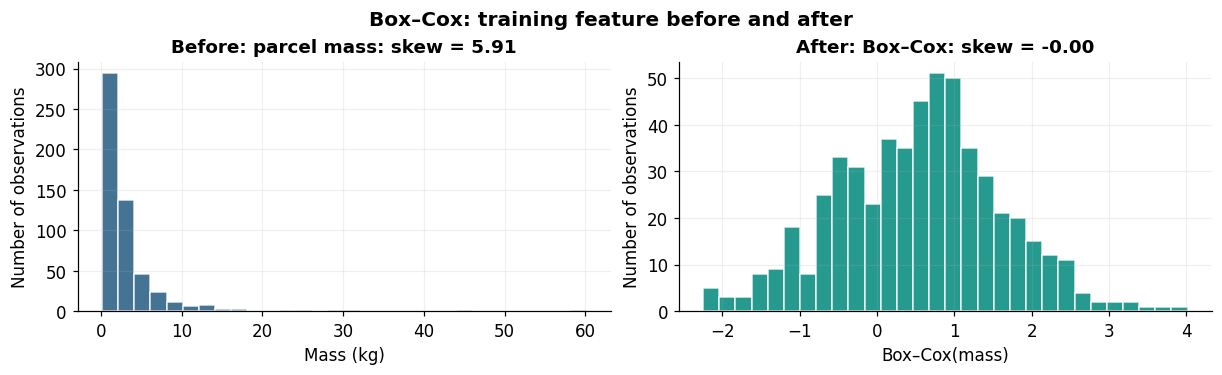

,Minimum,Median,Maximum,Sample skewness
Raw mass,0.1082,1.8739,60.1438,5.9114
Box–Cox,-2.2480,0.6261,4.0146,-0.0000


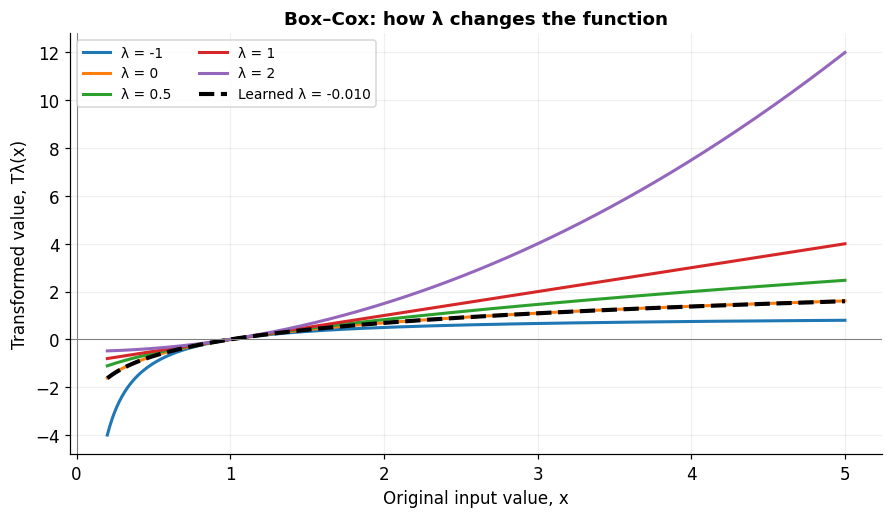

,Mass (kg),Using learned λ
0,0.25,-1.3959
1,1.00,0.0000
2,4.00,1.3768
3,10.00,2.2765
4,25.00,3.1680


In [10]:
assert (X_train > 0).all(), 'Box–Cox needs strictly positive inputs.'
bc = PowerTransformer(method='box-cox', standardize=False)
X_train_bc = bc.fit_transform(X_train)
X_val_bc = bc.transform(X_val)
bc_lambda = None
if bc is None or X_train_bc is None or X_val_bc is None:
    print('Exercise 4: create bc, fit_transform the training data, then transform validation data.')
else:
    assert bc.method == 'box-cox' and bc.standardize is False
    assert X_train_bc.shape == X_train.shape and X_val_bc.shape == X_val.shape
    assert np.isfinite(X_train_bc).all() and np.isfinite(X_val_bc).all()
    bc_lambda = float(bc.lambdas_[0])
    print(f'Learned Box–Cox λ, fitted on training parcels only: {bc_lambda:.6f}')
    histogram_grid({'Before: parcel mass': x_train, 'After: Box–Cox': X_train_bc.ravel()},
                   'Box–Cox: training feature before and after', labels={
                       'Before: parcel mass': 'Mass (kg)', 'After: Box–Cox': 'Box–Cox(mass)'})
    display(describe_views({'Raw mass': x_train, 'Box–Cox': X_train_bc.ravel()}).round(4))
    plot_power_family('box-cox', bc_lambda)
    probe = np.array([0.25, 1, 4, 10, 25]).reshape(-1, 1)
    display(pd.DataFrame({'Mass (kg)': probe.ravel(),
                          'Using learned λ': bc.transform(probe).ravel()}).round(4))


,Validation MSE (seconds²)
log1p,12.734
Square root,16.420
Box–Cox,21.347
Raw,48.211


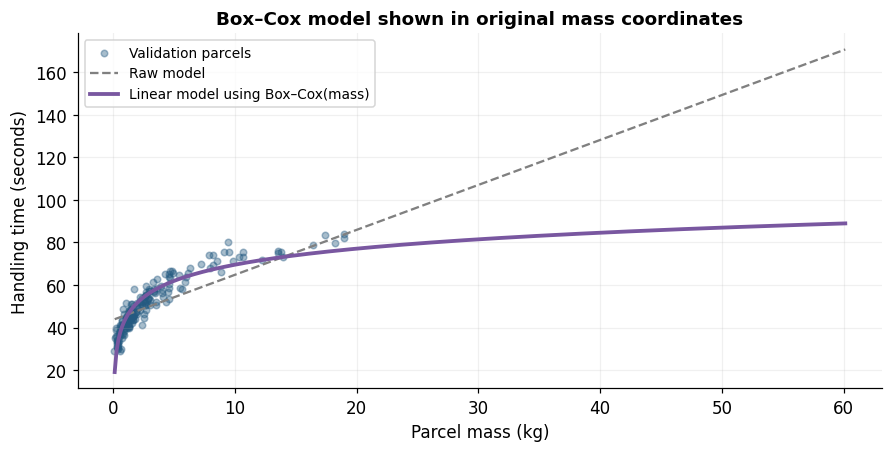

In [11]:
# Provided comparison: train the same linear algorithm on the Box–Cox feature.
if bc_lambda is None:
    print('Complete the Box–Cox cell above to add this model.')
else:
    bc_model = LinearRegression().fit(X_train_bc, y_train)
    bc_validation_prediction = bc_model.predict(X_val_bc)
    model_registry['Box–Cox'] = (bc_model, bc.transform)
    validation_scores['Box–Cox'] = mean_squared_error(y_val, bc_validation_prediction)
    display(validation_table().round(3))

    grid = np.linspace(X_train.min(), X_train.max(), 400).reshape(-1, 1)
    fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
    ax.scatter(X_val.ravel(), y_val, s=18, alpha=0.4, color=BLUE, label='Validation parcels')
    ax.plot(grid.ravel(), raw_model.predict(grid), color='grey', linestyle='--', label='Raw model')
    ax.plot(grid.ravel(), bc_model.predict(bc.transform(grid)), color=PURPLE, linewidth=2.5,
            label='Linear model using Box–Cox(mass)')
    ax.set(title='Box–Cox model shown in original mass coordinates', xlabel='Parcel mass (kg)',
           ylabel='Handling time (seconds)')
    ax.legend(fontsize=9)
    plt.show()


**Discuss and record your answers**

1. What λ did the method learn? Is it closest to 0, 0.5 or 1? What do those three values mean?
2. Can a valid Box–Cox output be negative when the input is positive?
3. Does a more symmetric mass distribution give the smallest prediction MSE in this example?
4. Why must you reuse the fitted `bc` to transform validation or future parcels?


**Lecturer solution**

1. The saved run learns **λ ≈ −0.009919**, close to 0 and therefore close to `ln(x)`.
   λ = 0 is natural log, λ = 0.5 is `2 * (sqrt(x) - 1)`, and λ = 1 is `x - 1`.
   Box–Cox with λ = 0 uses `ln(x)`, which differs from the `ln(1+x)` in Exercise 2.
2. Yes. For example, every Box–Cox family curve maps 1 to 0, and positive inputs below 1
   map to negative outputs. The restriction concerns the input, not the output.
3. Box–Cox makes mass much more symmetric, but its validation MSE is approximately **21.347**,
   above the log1p model's **12.734**. The feature likelihood criterion and prediction MSE
   answer different questions. A normal-looking feature does not guarantee the best predictions.
4. λ is a learned preprocessing parameter. Refitting on validation data leaks information and
   gives the model inputs in a different feature representation from the one used for training.
   Split first, learn on training data, and apply the same transformation to unseen data.


## Exercise 5 · Yeo–Johnson for signed stock changes · 14 minutes
**Slide 13.** Switch to the separate `daily_stock` dataset. Box–Cox cannot accept its zero or negative
inputs. Yeo–Johnson handles negative, zero and positive values without adding an arbitrary offset.

First inspect the supplied histogram and sign counts. Then complete the four lines in the next cell:
create `PowerTransformer(method='yeo-johnson', standardize=False)`, fit/transform `S_train`,
transform `S_holdout`, and use `inverse_transform` to recover the training inputs.

The plots use the complete family from slide 13, including its negative-input branch.
Some useful facts with **standardisation disabled**:

| λ | Interpretation |
| --- | --- |
| 1 | Identity on all real inputs: $T_1(x)=x$ |
| Less than 1 | Compresses positive values relative to identity and expands negative magnitudes |
| Greater than 1 | Expands positive values and compresses negative magnitudes |

All family members map zero to zero. They preserve order, but change distances.
The method aims to improve distribution shape. It cannot guarantee normality or remove a point mass at zero.


,Count
Negative training values,171
Exact zeros in training,21
Positive training values,288


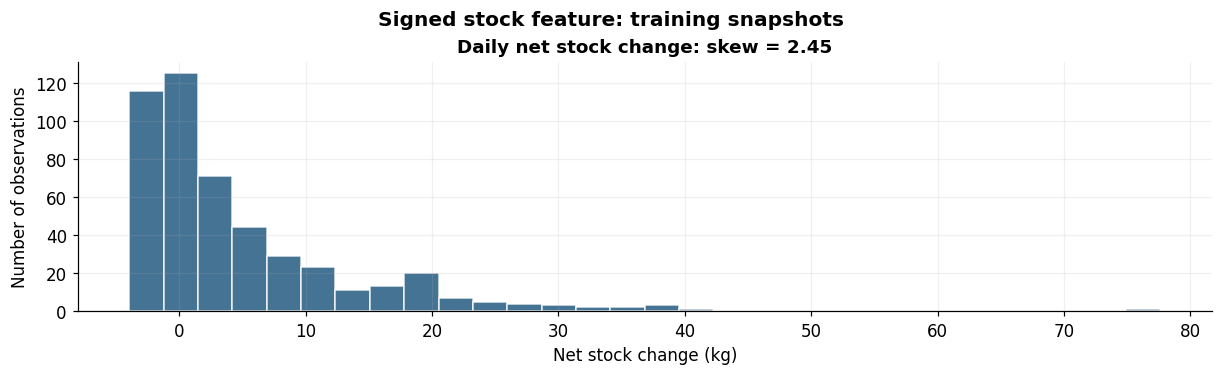

In [12]:
# Provided inspection. The holdout snapshots remain separate from lambda fitting.
stock_training = S_train.ravel()
display(pd.Series({
    'Negative training values': int(np.sum(stock_training < 0)),
    'Exact zeros in training': int(np.sum(stock_training == 0)),
    'Positive training values': int(np.sum(stock_training > 0)),
}).to_frame('Count'))
histogram_grid({'Daily net stock change': stock_training}, 'Signed stock feature: training snapshots',
               labels={'Daily net stock change': 'Net stock change (kg)'})


Learned Yeo–Johnson λ, fitted on training stock snapshots only: 0.478870
Self-checks passed: finite outputs, preserved ordering, zero stays zero, and inverse works.


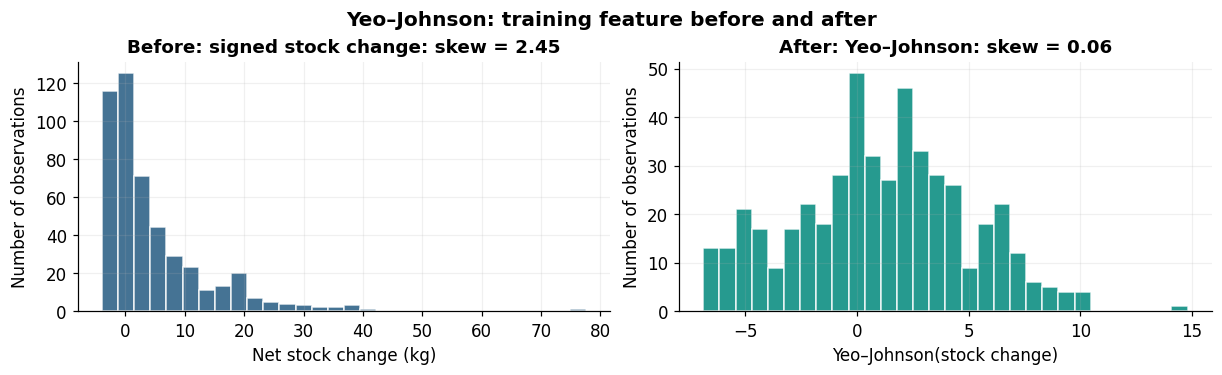

,Minimum,Median,Maximum,Sample skewness
Training: raw,-3.9660,1.4212,77.6240,2.4547
Training: Yeo–Johnson,-6.8683,1.1009,14.7970,0.0562
Holdout: raw,-3.8408,0.6839,44.0217,2.1745
Holdout: Yeo–Johnson,-6.5817,0.5919,10.8405,0.1371


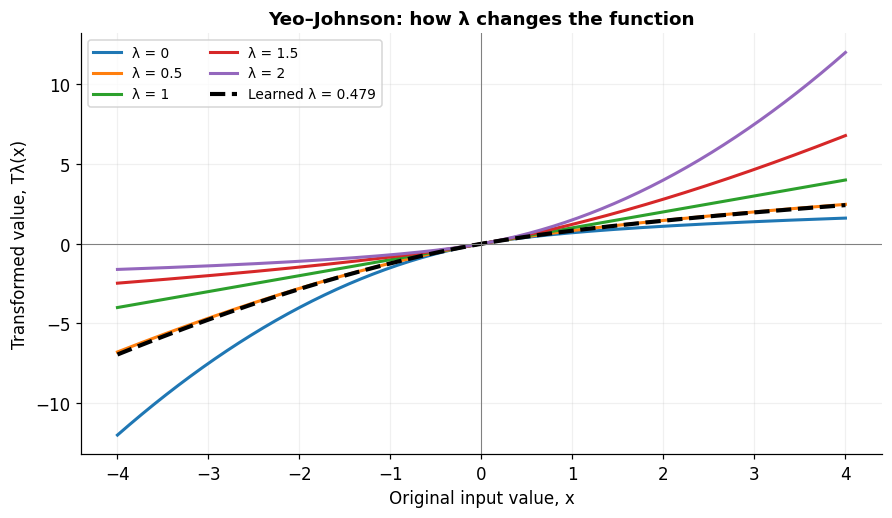

,Original stock change (kg),Transformed,Recovered (kg)
0,-3.0,-4.7582,-3.0
1,-1.0,-1.2295,-1.0
2,0.0,0.0000,0.0
3,1.0,0.8220,1.0
4,6.0,3.2142,6.0


In [13]:
yj = PowerTransformer(method='yeo-johnson', standardize=False)
S_train_yj = yj.fit_transform(S_train)
S_holdout_yj = yj.transform(S_holdout)
S_recovered = yj.inverse_transform(S_train_yj)
yj_lambda = None
if any(value is None for value in (yj, S_train_yj, S_holdout_yj, S_recovered)):
    print('Exercise 5: complete the four TODO values to see the Yeo–Johnson results.')
else:
    assert yj.method == 'yeo-johnson' and yj.standardize is False
    assert S_train_yj.shape == S_train.shape and S_holdout_yj.shape == S_holdout.shape
    assert np.isfinite(S_train_yj).all() and np.isfinite(S_holdout_yj).all()
    assert np.allclose(S_recovered, S_train), 'Check inverse_transform.'
    assert np.allclose(yj.transform([[0.0]]), 0.0), 'Use standardize=False.'
    order = np.argsort(S_train.ravel())
    assert np.all(np.diff(S_train_yj.ravel()[order]) >= -1e-12)
    yj_lambda = float(yj.lambdas_[0])
    print(f'Learned Yeo–Johnson λ, fitted on training stock snapshots only: {yj_lambda:.6f}')
    histogram_grid({'Before: signed stock change': S_train.ravel(),
                    'After: Yeo–Johnson': S_train_yj.ravel()},
                   'Yeo–Johnson: training feature before and after', labels={
                       'Before: signed stock change': 'Net stock change (kg)',
                       'After: Yeo–Johnson': 'Yeo–Johnson(stock change)'})
    display(describe_views({'Training: raw': S_train.ravel(),
                           'Training: Yeo–Johnson': S_train_yj.ravel(),
                           'Holdout: raw': S_holdout.ravel(),
                           'Holdout: Yeo–Johnson': S_holdout_yj.ravel()}).round(4))
    plot_power_family('yeo-johnson', yj_lambda)
    probe = np.array([-3.0, -1.0, 0.0, 1.0, 6.0]).reshape(-1, 1)
    probe_transformed = yj.transform(probe)
    display(pd.DataFrame({'Original stock change (kg)': probe.ravel(),
                          'Transformed': probe_transformed.ravel(),
                          'Recovered (kg)': yj.inverse_transform(probe_transformed).ravel()}).round(4))
    print('Self-checks passed: finite outputs, preserved ordering, zero stays zero, and inverse works.')


**Discuss and record your answers**

1. What λ was learned? Does it compress or expand the positive side relative to identity?
2. Why are ordinary log, `log1p`, square root and Box–Cox unsuitable for this entire signed feature?
3. What happens to zero and to the original ordering? Does lower skewness prove normality?
4. Why are there no MSE numbers for the daily-stock transformation?


**Lecturer solution**

1. The saved run learns **λ ≈ 0.478870**. Since it is below 1, it compresses the positive tail and
   expands negative magnitudes relative to identity. It differs from the Box–Cox λ because the
   feature distribution and the transformation family differ.
2. Ordinary log and Box–Cox require strictly positive inputs. Real square root requires nonnegative
   inputs. Log1p requires inputs greater than −1, but some stock changes are below −1.
   Yeo–Johnson supports all these observed values directly. Making everything positive by taking
   absolute values would erase the operational distinction between net arrivals and net departures.
3. Zero remains zero and ordering is preserved. Training skewness changes from approximately **2.455**
   to **0.056**, but this is not proof of normality. The intentionally repeated zero values remain repeated.
   Distribution diagnostics on the holdout use the training-fitted λ without changing it.
4. This separate dataset has no prediction target. We are examining feature shape and a reversible
   mapping. The parcel model's MSE is a prediction measure for a different dataset and task.


## Exercise 6 · Recommend and check · 5 minutes
**Slides 8 and 11–13.** Use the **validation** comparison to choose among the four completed parcel
models. Run the provided final check to evaluate that already-fitted model on the reserved test set.
The cell also evaluates the pre-specified raw baseline for context. Avoid changing the choice after
seeing these test results. In a larger project, choose alternatives using cross-validation first.

Complete the short exit questions below. If a previous task is unfinished, return to it before running
the final check.


Selected from validation data: log1p
Reserved test MSE: 13.123 seconds²
Reserved test RMSE: 3.623 seconds
Pre-specified raw baseline test MSE: 55.246 seconds²


,Validation MSE (seconds²)
log1p,12.734
Square root,16.420
Box–Cox,21.347
Raw,48.211


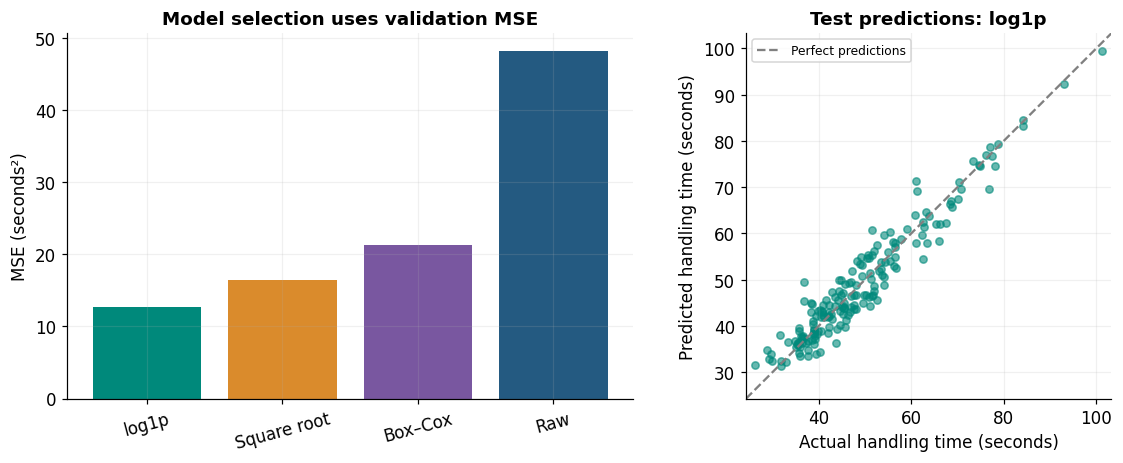

In [14]:
required_candidates = {'Raw', 'log1p', 'Square root', 'Box–Cox'}
selected_name = None
final_test_mse = None
if not required_candidates.issubset(model_registry) or yj_lambda is None:
    print('Complete Exercises 3, 4 and 5 before the final check.')
else:
    comparison = validation_table()
    display(comparison.round(3))
    selected_name = comparison.index[0]  # choose using validation scores only
    selected_model, selected_transform = model_registry[selected_name]
    final_prediction = selected_model.predict(selected_transform(X_test))
    final_test_mse = mean_squared_error(y_test, final_prediction)
    raw_test_mse = mean_squared_error(y_test, raw_model.predict(X_test))
    print(f'Selected from validation data: {selected_name}')
    print(f'Reserved test MSE: {final_test_mse:.3f} seconds²')
    print(f'Reserved test RMSE: {np.sqrt(final_test_mse):.3f} seconds')
    print(f'Pre-specified raw baseline test MSE: {raw_test_mse:.3f} seconds²')

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), layout='constrained')
    axes[0].bar(comparison.index, comparison.iloc[:, 0], color=[TEAL, ORANGE, PURPLE, BLUE])
    axes[0].set(title='Model selection uses validation MSE', ylabel='MSE (seconds²)')
    axes[0].tick_params(axis='x', rotation=15)
    axes[1].scatter(y_test, final_prediction, s=23, color=TEAL, alpha=0.6)
    limits = [min(y_test.min(), final_prediction.min()) - 2,
              max(y_test.max(), final_prediction.max()) + 2]
    axes[1].plot(limits, limits, '--', color='grey', label='Perfect predictions')
    axes[1].set(xlim=limits, ylim=limits, title=f'Test predictions: {selected_name}',
                xlabel='Actual handling time (seconds)', ylabel='Predicted handling time (seconds)')
    axes[1].set_aspect('equal', adjustable='box')
    axes[1].legend(fontsize=8)
    plt.show()


**Discuss and record your answers**

1. Recommend a transformation for parcel-mass prediction and one for signed stock changes.
   Support your recommendations with the relevant results.
2. Explain why a Box–Cox λ close to zero did not make it identical to the log1p model.
3. State one way to avoid data leakage and one reason a transformation may fail to improve a model.


**Lecturer solution**

1. For this simulated parcel task, choose log1p because it has the smallest validation MSE.
   Use the printed reserved-test MSE as a final estimate for that choice. For signed stock,
   Yeo–Johnson accepts the full input domain and substantially reduces observed training skewness.
   Without a stock target, we can recommend it as a candidate preprocessing step, rather than
   claim it improves stock prediction.
2. Box–Cox near λ = 0 approximates `ln(mass)`. Log1p uses `ln(1 + mass)`. These differ most at
   small masses, which are common in this dataset. The synthetic target was generated with log1p.
3. Learn λ only on training data and apply the same fitted transformer to unseen data.
   Reducing input skewness may worsen the input–target relationship, so evaluate the intended model.
   A more symmetric marginal feature is not a guarantee of lower prediction error.


## Optional exercises for early finishers
Start these only after finishing the core work. Set **`RUN_OPTIONAL = True`** in the imports cell,
rerun that cell, and then run the optional cells you want to attempt. You do not need to rerun the
data-generation cell. The following work uses the existing training/validation data and does not
reopen the reserved parcel test set.


### Optional A · Domains and the power-family formulas · extra 20 minutes
**Slides 8, 12 and 13.** There are two parts:

1. Complete the six expressions in `domain_views` for the toy values below, using `np.log`, `np.sqrt`,
   reciprocal, square, division by 5 and `np.exp`. Interpret any `NaN` or infinite values.
   Use this small toy range for the exponential, rather than exponentiating large parcel masses.
2. Implement `boxcox_manual` and `yeojohnson_manual` from the lecture formulas. Include the log branches
   for Box–Cox λ = 0 and Yeo–Johnson λ = 0 or 2. Box–Cox must raise `ValueError` for any nonpositive input.
   Use boolean masks for the Yeo–Johnson positive/negative branches. `np.expm1(z)` computes $e^z-1$
   accurately when $z$ is near zero.

The supplied checks compare several λ values and both input signs against SciPy, including special cases.


In [15]:
if RUN_OPTIONAL:
    toy = np.array([-2.0, -1.0, 0.0, 0.25, 1.0, 4.0])
    with np.errstate(divide='ignore', invalid='ignore'):
        domain_views = {
            'Natural log': np.log(toy),
            'Square root': np.sqrt(toy),
            'Reciprocal': 1 / toy,
            'Square': toy**2,
            'Linear scaling': toy / 5,
            'Exponential': np.exp(toy),
        }
    if any(values is None for values in domain_views.values()):
        print('Optional A: complete the six domain expressions.')
    else:
        domain_table = pd.DataFrame(domain_views, index=toy)
        domain_table.index.name = 'Input x'
        display(domain_table.round(4))
        print('Non-finite entries, marking invalid real outputs or a singularity:')
        display((~np.isfinite(domain_table)).astype(int))
else:
    print('Optional A skipped. Set RUN_OPTIONAL = True to start.')


Non-finite entries, marking invalid real outputs or a singularity:


,Natural log,Square root,Reciprocal,Square,Linear scaling,Exponential
Input x,,,,,,
-2.00,NaN,NaN,-0.50,4.0000,-0.40,0.1353
-1.00,NaN,NaN,-1.00,1.0000,-0.20,0.3679
0.00,-inf,0.0,inf,0.0000,0.00,1.0000
0.25,-1.3863,0.5,4.00,0.0625,0.05,1.2840
1.00,0.0000,1.0,1.00,1.0000,0.20,2.7183
4.00,1.3863,2.0,0.25,16.0000,0.80,54.5982


,Natural log,Square root,Reciprocal,Square,Linear scaling,Exponential
Input x,,,,,,
-2.00,1,1,0,0,0,0
-1.00,1,1,0,0,0,0
0.00,1,0,1,0,0,0
0.25,0,0,0,0,0,0
1.00,0,0,0,0,0,0
4.00,0,0,0,0,0,0


In [16]:
def boxcox_manual(values, lam):
    values = np.asarray(values, dtype=float)
    if np.any(values <= 0):
        raise ValueError('Box–Cox requires every input to be strictly positive.')
    if lam == 0:
        return np.log(values)
    return np.expm1(lam * np.log(values)) / lam

def yeojohnson_manual(values, lam):
    values = np.asarray(values, dtype=float)
    result = np.empty_like(values)
    positive = values >= 0
    if lam == 0:
        result[positive] = np.log1p(values[positive])
    else:
        result[positive] = np.expm1(lam * np.log1p(values[positive])) / lam
    if lam == 2:
        result[~positive] = -np.log1p(-values[~positive])
    else:
        result[~positive] = -np.expm1((2 - lam) * np.log1p(-values[~positive])) / (2 - lam)
    return result

if RUN_OPTIONAL:
    positive_probe = np.array([0.1, 0.5, 1, 3, 10])
    signed_probe = np.array([-4, -0.5, 0, 0.5, 4], dtype=float)
    if boxcox_manual(positive_probe, 0) is None or yeojohnson_manual(signed_probe, 1) is None:
        print('Optional A: implement both functions, then rerun this cell.')
    else:
        for lam in [-1, 0, 0.5, 1, 2]:
            assert np.allclose(boxcox_manual(positive_probe, lam),
                               stats.boxcox(positive_probe, lmbda=lam))
            assert np.allclose(yeojohnson_manual(signed_probe, lam),
                               stats.yeojohnson(signed_probe, lmbda=lam))
        for invalid in [np.array([0.0, 1.0]), np.array([-1.0, 1.0])]:
            try:
                boxcox_manual(invalid, 0.5)
            except ValueError:
                pass
            else:
                raise AssertionError('Box–Cox must reject zero and negative inputs.')
        print('All formula and domain checks passed.')
        display(pd.DataFrame({f'Yeo–Johnson λ={lam:g}': yeojohnson_manual(signed_probe, lam)
                              for lam in [0, 0.5, 1, 2]}, index=signed_probe).round(4))
else:
    print('Optional A formula implementation skipped.')


All formula and domain checks passed.


,Yeo–Johnson λ=0,Yeo–Johnson λ=0.5,Yeo–Johnson λ=1,Yeo–Johnson λ=2
-4.0,-12.0000,-6.7869,-4.0,-1.6094
-0.5,-0.6250,-0.5581,-0.5,-0.4055
0.0,0.0000,0.0000,0.0,0.0000
0.5,0.4055,0.4495,0.5,0.6250
4.0,1.6094,2.4721,4.0,12.0000


**Discuss and record your answers**

Why do squaring and taking absolute values lose information about signed stock changes?
Which methods reverse ordering, preserve ordering, or have a restricted domain?


**Lecturer solution**

A loss of 2 kg and a gain of 2 kg both become 4 when squared, or 2 after absolute value.
This erases the direction of the change. Log, square root and reciprocal have domain restrictions.
Reciprocal is decreasing on the positive branch, so it reverses positive-value order.
Positive linear scaling, log, square root and exponential are increasing on their relevant domains.
Square is not one-to-one on all real inputs. Box–Cox is increasing for positive inputs for every λ,
while Yeo–Johnson is increasing across the real line for every λ.
NumPy represents undefined real operations or singularities with NaN/inf in this controlled probe;
those are diagnostics, rather than usable model inputs.


### Optional B · Pipelines and cross-validation · extra 15 minutes
**Extension of slides 11–13.** A pipeline makes preprocessing part of model training.
Complete the four missing pipeline definitions. Use `FunctionTransformer` for fixed log1p/square root
and `PowerTransformer` for Box–Cox/Yeo–Johnson, each followed by `LinearRegression()`.

Use five-fold cross-validation on **`X_train` and `y_train` only**. The provided loop uses the same
folds for each method. In a pipeline, each power transform learns λ on that fold's training portion.
Fitting a transformer on all rows before cross-validation would leak information across the folds.
The scikit-learn scorer returns negative MSE because its scoring interface treats larger as better.
Negate it to report ordinary, positive MSE.


,Mean CV MSE (seconds²),Fold SD (seconds²)
Feature,,
log1p,12.907,1.218
Square root,19.204,7.009
Yeo–Johnson,21.236,4.385
Box–Cox,22.145,3.259
Raw,74.165,54.826


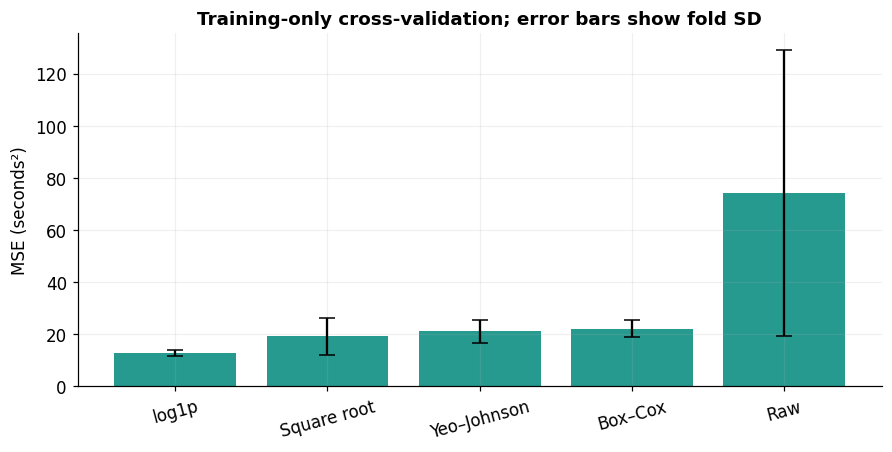

In [17]:
if RUN_OPTIONAL:
    cv_candidates = {
        'Raw': LinearRegression(),
        'log1p': make_pipeline(FunctionTransformer(np.log1p), LinearRegression()),
        'Square root': make_pipeline(FunctionTransformer(np.sqrt), LinearRegression()),
        'Box–Cox': make_pipeline(PowerTransformer(method='box-cox', standardize=False), LinearRegression()),
        'Yeo–Johnson': make_pipeline(PowerTransformer(method='yeo-johnson', standardize=False), LinearRegression()),
    }
    if any(model is None for model in cv_candidates.values()):
        print('Optional B: complete the four pipelines.')
    else:
        folds = KFold(n_splits=5, shuffle=True, random_state=SEED)
        cv_rows = []
        for name, estimator in cv_candidates.items():
            fold_mse = -cross_val_score(estimator, X_train, y_train, cv=folds,
                                        scoring='neg_mean_squared_error')
            cv_rows.append({'Feature': name, 'Mean CV MSE (seconds²)': fold_mse.mean(),
                            'Fold SD (seconds²)': fold_mse.std(ddof=1)})
        cv_results = pd.DataFrame(cv_rows).set_index('Feature').sort_values('Mean CV MSE (seconds²)')
        display(cv_results.round(3))
        fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
        ax.bar(cv_results.index, cv_results.iloc[:, 0], yerr=cv_results.iloc[:, 1],
               color=TEAL, alpha=0.85, capsize=5)
        ax.set(title='Training-only cross-validation; error bars show fold SD', ylabel='MSE (seconds²)')
        ax.tick_params(axis='x', rotation=15)
        plt.show()
else:
    print('Optional B skipped. Set RUN_OPTIONAL = True to start.')


**Discuss and record your answers**

Does cross-validation support your earlier transformation choice? Why does λ need to be learned
separately within each fold? Are the error bars confidence intervals?


**Lecturer solution**

Compare the mean CV MSE values with the earlier validation ranking. In this deliberately log-shaped
example, log1p is expected to perform well, but individual split scores vary. Yeo–Johnson can also
be applied to these strictly positive masses: supporting signed inputs does not prevent positive use.
Each fold simulates unseen data. Fitting λ on the full dataset would let the fold's held-out values
influence preprocessing. Pipelines avoid that leakage. The displayed error bars are the standard
deviation of the five fold scores, not confidence intervals, and the overlapping training folds mean
these scores are not independent replications.


### Optional C · When a transformation makes prediction worse · extra 10 minutes
**Extension of slides 8 and 11–12.** Keep exactly the same skewed masses and the same split indices,
but simulate a **different target** that is linear in raw mass. Complete the model-fitting loop below
for raw, log1p, square-root and Box–Cox representations. Fit each model on training rows and report
validation MSE. Use the existing training-fitted `bc` for Box–Cox.

Compare this result with Exercise 3. Explain why the best feature representation changes even though
the input histogram has not changed. Do not change the original `y_train`, `y_val` or chosen model.


,Validation MSE (seconds²)
Feature,
Raw,10.995
Square root,60.705
log1p,95.754
Box–Cox,175.522


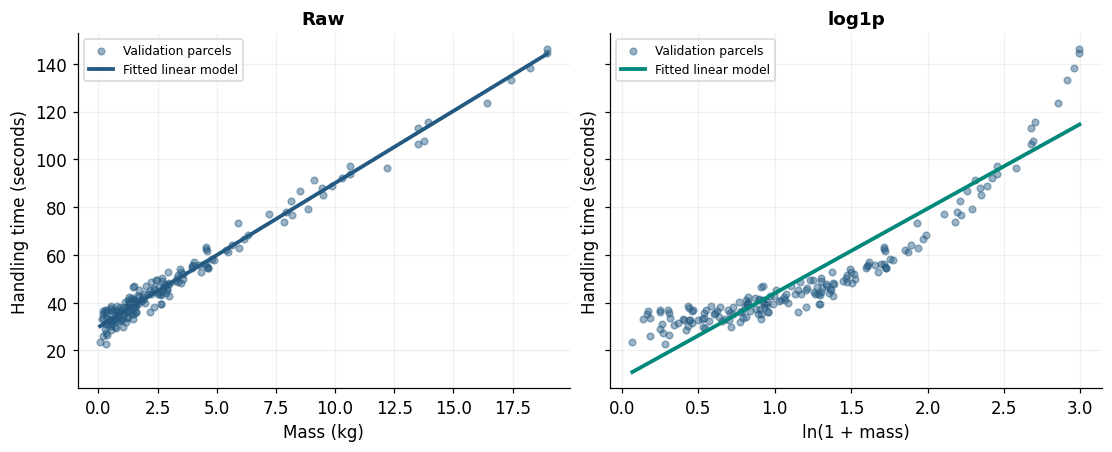

In [18]:
if RUN_OPTIONAL:
    if bc_lambda is None:
        print('Complete Exercise 4 before Optional C.')
    else:
        challenge_rng = np.random.default_rng(404)
        linear_target = 30 + 6 * X.ravel() + challenge_rng.normal(0, 3.5, len(X))
        c_y_train, c_y_val = linear_target[train_idx], linear_target[val_idx]
        c_rows = []
        c_registry = {}
        for name, transform in [('Raw', lambda values: values), ('log1p', np.log1p),
                                ('Square root', np.sqrt), ('Box–Cox', bc.transform)]:
            c_model = LinearRegression().fit(transform(X_train), c_y_train)
            c_prediction = c_model.predict(transform(X_val))
            c_mse = mean_squared_error(c_y_val, c_prediction)
            if c_model is None or c_prediction is None or c_mse is None:
                print(f'Optional C, {name}: complete the three TODO lines.')
            else:
                c_registry[name] = (c_model, transform)
                c_rows.append({'Feature': name, 'Validation MSE (seconds²)': c_mse})
        if len(c_rows) == 4:
            c_results = pd.DataFrame(c_rows).set_index('Feature').sort_values('Validation MSE (seconds²)')
            display(c_results.round(3))
            plot_model_fits(c_registry, ['Raw', 'log1p'], X_val, c_y_val)
else:
    print('Optional C skipped. Set RUN_OPTIONAL = True to start.')


**Discuss and record your answers**

Which representation works best now? What does this tell you about choosing transformations from
a feature histogram alone?


**Lecturer solution**

Raw mass now gives the smallest validation MSE because the new target is linear in that feature.
Applying log1p, square root or Box–Cox bends a relationship that was already suitable for a straight
line. The predictor distribution is still skewed, which does not prevent good prediction.
Inspect the input–target relationship and evaluate the intended model, rather than choosing solely
by how normal the input histogram looks.


## What to hand in or keep for revision
Keep your completed code, before/after plots, the learned λ for each method, the parcel-model
comparison table, and your Exercise 6 recommendation. Record any optional work separately.
If you run out of time, write what you would try next and what you expect it to show.

## Further reading
- [scikit-learn: PowerTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html)
- [SciPy: Box–Cox formula and API](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.boxcox.html)
- [SciPy: Yeo–Johnson formula and API](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.yeojohnson.html)
- [scikit-learn: avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

Lecture alignment: Dr Hamid Nasiri, `Week04_Lecture01_Feature_Engineering_PartA.pptx`, slides 8–13.
All datasets in this workbook are synthetic. Saved solution outputs come from the fixed seeds above.
